Título, Contexto de Negócio e Objetivo

In [23]:
!pip install -q shap imbalanced-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score
)

In [24]:
df = pd.read_csv("https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv")

df.info()
df.duplicated().sum()
df['Class'].value_counts(normalize=True)

#devido ao alto número de duplicatas decidi fazer a seguinte linha:
df = df.drop_duplicates()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

Análise Exploratória (EDA)

<Axes: xlabel='Hour', ylabel='Density'>

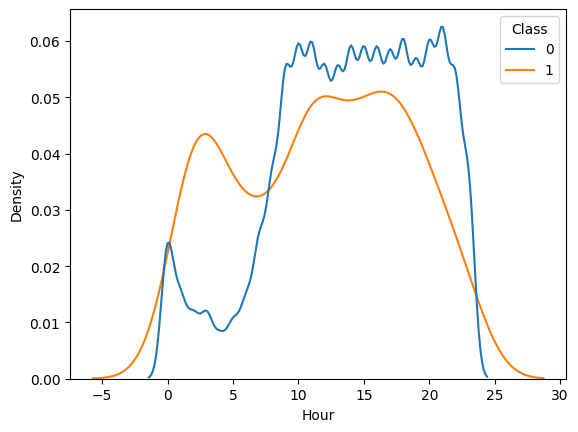

In [25]:
df['Hour'] = (df['Time'] // 3600) % 24
sns.kdeplot(data=df, x='Hour', hue='Class', common_norm=False)

In [26]:
df.groupby('Class')['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


Pré-processamento e Split Estratificado

In [27]:
df['log_amount'] = np.log1p(df['Amount'])
X = df.drop(columns=['Class', 'Time', 'Amount'])
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Modelagem Baseline vs. Modelos com Peso de Classe

In [28]:

pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])


pipe_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1))
])


peso = (y_train == 0).sum() / (y_train == 1).sum()
pipe_xgb = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', XGBClassifier(scale_pos_weight=peso, random_state=42, n_jobs=-1))
])



In [20]:
modelos = {
    "Regressão Logística": pipe_lr,
    "Random Forest (Balanced)": pipe_rf,
    "XGBoost (Weighted)": pipe_xgb
}

for nome, modelo in modelos.items():
    print(f"=== {nome} ===")
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]

    print(classification_report(y_test, y_pred))
    print(f"Average Precision (PR-AUC): {average_precision_score(y_test, y_prob):.4f}\n")

=== Regressão Logística ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.85      0.59      0.70        95

    accuracy                           1.00     56746
   macro avg       0.92      0.79      0.85     56746
weighted avg       1.00      1.00      1.00     56746

Average Precision (PR-AUC): 0.6963

=== Random Forest (Balanced) ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.97      0.71      0.82        95

    accuracy                           1.00     56746
   macro avg       0.99      0.85      0.91     56746
weighted avg       1.00      1.00      1.00     56746

Average Precision (PR-AUC): 0.8005

=== XGBoost (Weighted) ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.94      0.77      0.84        95

    accuracy          

Otimização com Pipeline, GridSearchCV e Ajuste de Limiar

Treinando GridSearchCV com foco em Recall...
Melhores hiperparâmetros encontrados: {'clf__C': 0.1, 'clf__class_weight': 'balanced'}

=== Modelo Otimizado (Limiar Padrão = 0.5) ===
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.06      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.97      0.99     56746


=== Modelo Otimizado com Limiar Ajustado (0.3) ===
              precision    recall  f1-score   support

           0       1.00      0.94      0.97     56651
           1       0.03      0.87      0.05        95

    accuracy                           0.94     56746
   macro avg       0.51      0.91      0.51     56746
weighted avg       1.00      0.94      0.97     56746



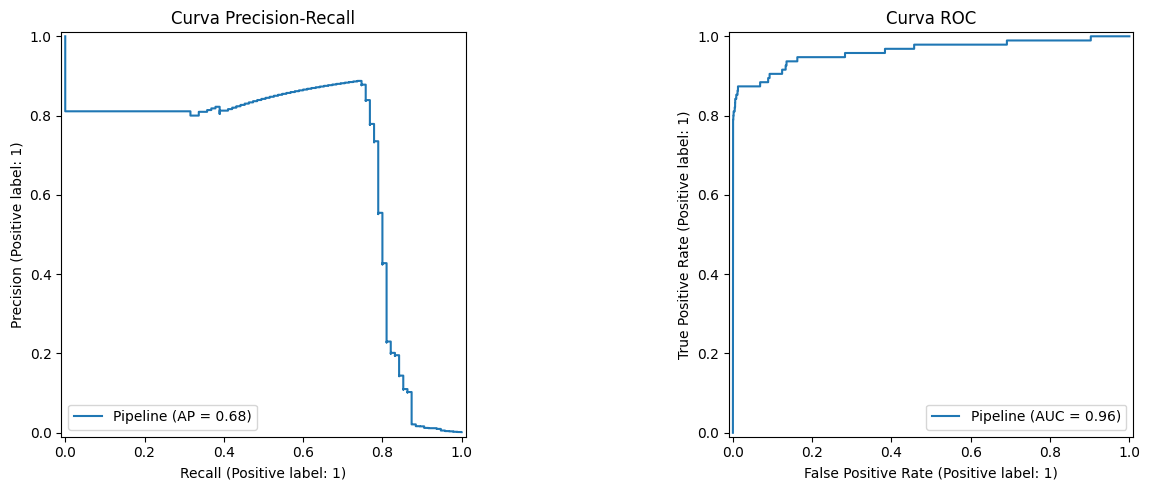

In [21]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_recall_curve

# Vamos configurar um GridSearch para a Regressão Logística focado em otimizar Recall
# (ou você pode trocar para RandomForest/XGBoost se preferir, mas a Regressão Logística roda super rápido!)
param_grid = {
    'clf__C': [0.01, 0.1, 1.0, 10.0],
    'clf__class_weight': ['balanced', None]
}

grid_search = GridSearchCV(
    pipe_lr,
    param_grid,
    scoring='recall',
    cv=3,
    n_jobs=-1
)

print("Treinando GridSearchCV com foco em Recall...")
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print(f"Melhores hiperparâmetros encontrados: {grid_search.best_params_}")

# Predições com o limiar padrão (0.5)
y_prob_best = best_model.predict_proba(X_test)[:, 1]
y_pred_default = (y_prob_best >= 0.5).astype(int)

print("\n=== Modelo Otimizado (Limiar Padrão = 0.5) ===")
print(classification_report(y_test, y_pred_default))

# Ajustando o limiar de decisão para 0.3 para capturar mais fraudes!
limiar = 0.3
y_pred_adjusted = (y_prob_best >= limiar).astype(int)

print(f"\n=== Modelo Otimizado com Limiar Ajustado ({limiar}) ===")
print(classification_report(y_test, y_pred_adjusted))

# Plotando as Curvas de Avaliação (ROC e Precision-Recall)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

PrecisionRecallDisplay.from_estimator(best_model, X_test, y_test, ax=ax1)
ax1.set_title('Curva Precision-Recall')

RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=ax2)
ax2.set_title('Curva ROC')

plt.tight_layout()
plt.show()

Explicabilidade do Modelo com SHAP

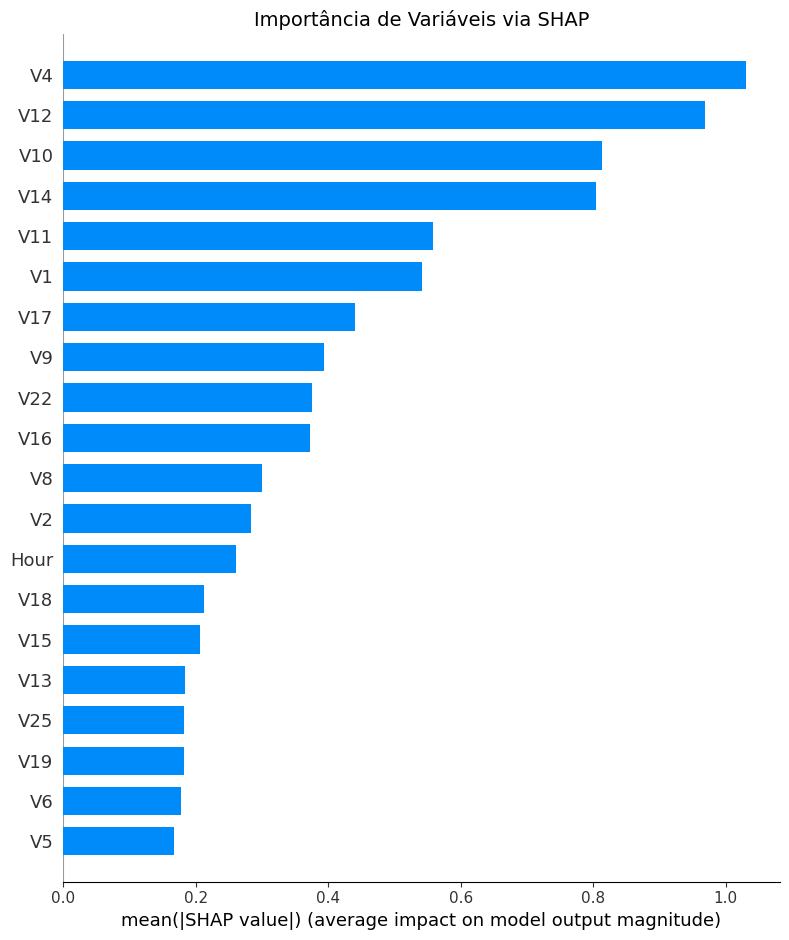

In [22]:
import shap

# Para acelerar o cálculo do SHAP, usamos uma amostra dos dados de teste
# e extraímos o classificador final após a escala padrão do pipeline
scaler = best_model.named_steps['scaler']
clf = best_model.named_steps['clf']

X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

# Selecionando uma amostra de 500 registros para o SHAP Explainer rodar rápido
X_sample = shap.sample(X_test_scaled, 500, random_state=42)

explainer = shap.Explainer(clf, X_sample)
shap_values = explainer(X_sample)

# Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_sample, plot_type="bar", show=False)
plt.title("Importância de Variáveis via SHAP", fontsize=14)
plt.tight_layout()
plt.show()

Conclusões e Próximos Passos

# Conclusões e Aprendizados do Projeto

- **O Desafio do Desbalanceamento:** Com apenas 0.17% de fraudes na base de dados, focar em Acurácia convencional não funciona (um modelo estúpido que prevê sempre 'não-fraude' teria 99.8% de acurácia, mas detectaria 0 fraudes).
- **Recall vs. Precisão:** Para o negócio de cartões de crédito, o custo de não detectar uma fraude (Falso Negativo) é muito alto. Por isso, priorizamos o aumento do **Recall** ajustando o limiar de decisão para `0.3`, aceitando uma leve perda na precisão em troca de pegar muito mais tentativas de fraude.
- **Transparência:** O uso de **SHAP** nos permite explicar aos órgãos reguladores e clientes quais características comportamentais (como as componentes V1-V28 extraídas por PCA e o log do valor) impactaram diretamente o score de risco do modelo.